# Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")      # izhodne datoteke simulacije (C++)

# Parametri simulacije (morajo ustrezati main.cpp)
N = 216                  # število delcev
rho = 0.8                # številska gostota (reducirane enote)
L = (N / rho)**(1 / 3)   # rob škatle (P2)
r_c = 2.5                # radij odreza

# Funkcije

In [2]:
def lj_potencial(r, eps=1.0, sig=1.0):
    """Lennard-Jonesov potencial V(r)."""
    x = (sig / r)**6
    return 4 * eps * (x**2 - x)


def lj_sila(r, eps=1.0, sig=1.0):
    """Velikost sile F(r) = -dV/dr (pozitivna = odbojna)."""
    x = (sig / r)**6
    return 24 * eps / r * (2 * x**2 - x)


def preberi_energije(ime):
    """Prebere CSV z energijami (Time, E_kin, E_pot, E_total, Temp)."""
    return pd.read_csv(DATA / ime)


def preberi_xyz(ime):
    """Prebere XYZ trajektorijo. Vrne (tipi, pozicije) z obliko pozicij (n_okvirjev, N, 3)."""
    vrstice = (DATA / ime).read_text().splitlines()
    n = int(vrstice[0])
    okvirji = len(vrstice) // (n + 2)
    tipi = np.array([vrstice[2 + k].split()[0] for k in range(n)])
    poz = np.empty((okvirji, n, 3))
    for f in range(okvirji):
        blok = vrstice[f * (n + 2) + 2:(f + 1) * (n + 2)]
        poz[f] = np.array([v.split()[1:4] for v in blok], dtype=float)
    return tipi, poz


def minimalna_slika(dr, L):
    """Minimalna slika: komponente dr preslika v interval [-L/2, L/2]."""
    return dr - L * np.round(dr / L)


def rdf(poz, L, r_max, n_bins=100):
    """Radialna porazdelitvena funkcija g(r), povprečena po okvirjih poz (n_okvirjev, N, 3).
    Vrne (r, g)."""
    M, n, _ = poz.shape
    robovi = np.linspace(0, r_max, n_bins + 1)
    stevec = np.zeros(n_bins)
    iu = np.triu_indices(n, k=1)                    # pari i < j
    for okvir in poz:
        dr = minimalna_slika(okvir[:, None, :] - okvir[None, :, :], L)
        r = np.linalg.norm(dr, axis=-1)[iu]
        stevec += np.histogram(r, bins=robovi)[0]
    r = 0.5 * (robovi[1:] + robovi[:-1])
    lupina = 4 / 3 * np.pi * (robovi[1:]**3 - robovi[:-1]**3)
    idealno = M * 0.5 * n * (n / L**3) * lupina
    g = stevec / idealno
    return r, g


def prvi_vrh_in_minimum(r, g):
    """Lega prvega vrha in prvega minimuma za njim."""
    k = int(np.argmax(g))
    m = k + int(np.argmin(g[k:k + int(1.0 / (r[1] - r[0]))]))
    return r[k], g[k], r[m]


def koordinacijsko_stevilo(r, g, rho, r_min):
    """Povprečno število sosedov do razdalje r_min: n = 4 pi rho int_0^r_min r^2 g(r) dr."""
    izb = r <= r_min
    return 4 * np.pi * rho * np.trapezoid(r[izb]**2 * g[izb], r[izb])

# Testno območje

In [3]:
r_m = 2**(1 / 6)
print(f"L = {L:.3f}, L/2 = {L/2:.3f} > r_c = {r_c}")
print(f"r_min = {r_m:.4f}, V(r_min) = {lj_potencial(r_m):.4f}, F(r_min) = {lj_sila(r_m):.2e}")
print(f"V(r_c) = {lj_potencial(r_c):.4f}")
print("minimalna slika:", minimalna_slika(np.array([0.9, -0.6, 0.2]) * L, L) / L)

L = 6.463, L/2 = 3.232 > r_c = 2.5
r_min = 1.1225, V(r_min) = -1.0000, F(r_min) = -2.37e-15
V(r_c) = -0.0163
minimalna slika: [-0.1  0.4  0.2]


# Naloga 1 - Slika 1

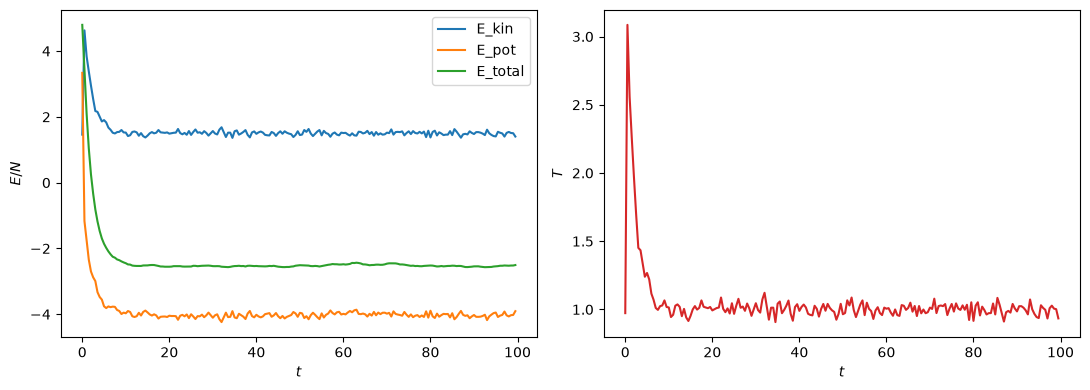

In [4]:
df = preberi_energije("nvt_T1.0.csv")
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
for st in ("E_kin", "E_pot", "E_total"):
    ax.plot(df["Time"], df[st] / N, label=st)
ax.set_xlabel("$t$")
ax.set_ylabel("$E/N$")
ax.legend()
ax = fig.add_subplot(122)
ax.plot(df["Time"], df["Temp"], color="tab:red")
ax.set_xlabel("$t$")
ax.set_ylabel("$T$")
fig.tight_layout()
plt.show()

In [5]:
# Preglednica 1 (povprečja po ekvilibraciji, t > 10)
ravn = df[df["Time"] > 10]
print(f"<T> = {ravn['Temp'].mean():.3f} +- {ravn['Temp'].std():.3f}")
print(f"<E_pot>/N = {ravn['E_pot'].mean()/N:.3f}, <E_kin>/N = {ravn['E_kin'].mean()/N:.3f}")
print(f"E_pot/N na začetku = {df['E_pot'].iloc[0]/N:.2f}")

<T> = 1.001 +- 0.040
<E_pot>/N = -4.026, <E_kin>/N = 1.501
E_pot/N na začetku = 3.34


# Naloga 2

In [6]:
koraki = [0.002, 0.005, 0.01, 0.015]
sigma_E = []
for dt in koraki:
    d = preberi_energije(f"nve_dt{dt}.csv")
    e = d[d["Time"] >= 10]["E_total"]
    sigma_E.append(e.std())
    print(f"dt = {dt:5}  <E> = {e.mean():8.2f}  sigma_E = {e.std():.4f}  sigma/|E| = {e.std()/abs(e.mean()):.1e}")
d = preberi_energije("nve_neprem_dt0.005.csv")
e = d[d["Time"] >= 10]["E_total"]
print(f"nepremaknjen potencial, dt = 0.005: sigma_E = {e.std():.4f}")

dt = 0.002  <E> =  -524.58  sigma_E = 0.0110  sigma/|E| = 2.1e-05
dt = 0.005  <E> =  -529.13  sigma_E = 0.0700  sigma/|E| = 1.3e-04
dt =  0.01  <E> =  -525.13  sigma_E = 0.2767  sigma/|E| = 5.3e-04
dt = 0.015  <E> =  -523.10  sigma_E = 0.6987  sigma/|E| = 1.3e-03
nepremaknjen potencial, dt = 0.005: sigma_E = 0.6056


# Naloga 2 - Slika 2

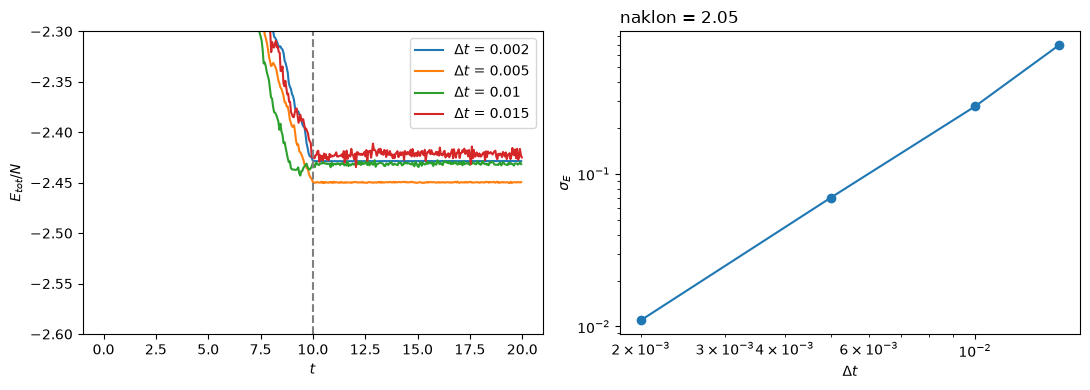

In [7]:
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
for dt in koraki:
    d = preberi_energije(f"nve_dt{dt}.csv")
    ax.plot(d["Time"], d["E_total"] / N, label=f"$\\Delta t$ = {dt}")
ax.axvline(10, color="gray", ls="--")
ax.set_ylim(-2.6, -2.3)
ax.set_xlabel("$t$")
ax.set_ylabel("$E_{tot}/N$")
ax.legend()
ax = fig.add_subplot(122)
ax.loglog(koraki, sigma_E, "o-")
k, n = np.polyfit(np.log10(koraki), np.log10(sigma_E), 1)
ax.set_title(f"naklon = {k:.2f}", loc="left")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel(r"$\sigma_E$")
fig.tight_layout()
plt.show()

# Naloga 3 - Slika 3

(50, 216, 3)


prvi vrh: r = 1.180, g = 2.60; prvi minimum: r = 1.632
koordinacijsko število n1 = 13.74


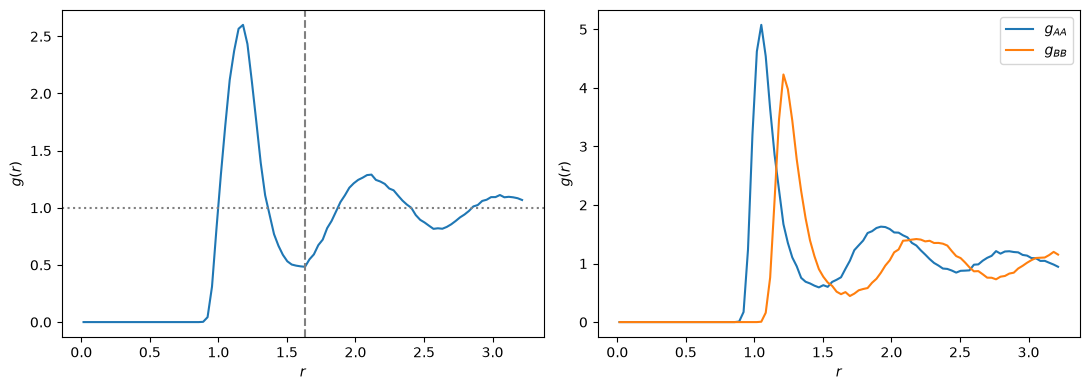

In [8]:
tipi, poz = preberi_xyz("traj_T1.0.xyz")
poz = poz[len(poz) // 2:]          # le okvirji po ekvilibraciji
print(poz.shape)
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
r, g = rdf(poz, L, L / 2)
r_v, g_v, r_mi = prvi_vrh_in_minimum(r, g)
ax.plot(r, g)
ax.axhline(1, color="gray", ls=":")
ax.axvline(r_mi, color="gray", ls="--")
ax.set_xlabel("$r$")
ax.set_ylabel("$g(r)$")
print(f"prvi vrh: r = {r_v:.3f}, g = {g_v:.2f}; prvi minimum: r = {r_mi:.3f}")
print(f"koordinacijsko število n1 = {koordinacijsko_stevilo(r, g, rho, r_mi):.2f}")
ax = fig.add_subplot(122)
for t in ("A", "B"):
    p = poz[:, tipi == t]
    rt, gt = rdf(p, L, L / 2)
    ax.plot(rt, gt, label=f"$g_{{{t}{t}}}$")
ax.set_xlabel("$r$")
ax.set_ylabel("$g(r)$")
ax.legend()
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 4

T = 0.5: <T> = 0.497, <E_pot>/N = -4.867, r_vrh = 1.212, g_vrh = 2.60, r_min1 = 1.535, n1 = 12.65


T = 1.0: <T> = 1.001, <E_pot>/N = -4.026, r_vrh = 1.180, g_vrh = 2.60, r_min1 = 1.632, n1 = 13.74


T = 2.0: <T> = 1.997, <E_pot>/N = -2.480, r_vrh = 1.147, g_vrh = 2.45, r_min1 = 1.567, n1 = 12.67


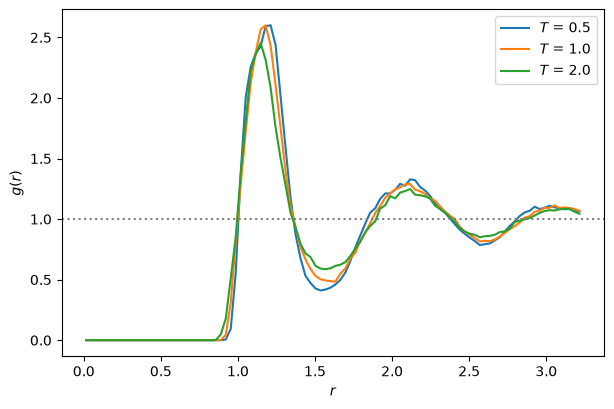

In [9]:
temperature = [0.5, 1.0, 2.0]
fig = plt.figure(figsize=(7, 4.5))
ax = fig.add_subplot(111)
for T in temperature:
    d = preberi_energije(f"nvt_T{T}.csv")
    d = d[d["Time"] > 10]
    _, p = preberi_xyz(f"traj_T{T}.xyz")
    r, g = rdf(p[len(p) // 2:], L, L / 2)
    r_v, g_v, r_mi = prvi_vrh_in_minimum(r, g)
    ax.plot(r, g, label=f"$T$ = {T}")
    print(f"T = {T}: <T> = {d['Temp'].mean():.3f}, <E_pot>/N = {d['E_pot'].mean()/N:.3f}, "
          f"r_vrh = {r_v:.3f}, g_vrh = {g_v:.2f}, r_min1 = {r_mi:.3f}, "
          f"n1 = {koordinacijsko_stevilo(r, g, rho, r_mi):.2f}")
ax.axhline(1, color="gray", ls=":")
ax.set_xlabel("$r$")
ax.set_ylabel("$g(r)$")
ax.legend()
plt.show()